# Online News Popularity: ML Challenge
Predict `target_popularity` (A–E). Metric: **Macro F1**.

**Final approach:** class-balanced LightGBM, hyperparameters tuned with Optuna, averaged over 5 random seeds, with class-probability weights tuned for Macro F1.

**Honest CV Macro F1 ≈ 0.330** (weights tuned on one half, scored on the other).

## Step 1 — Setup and load data

In [1]:
import pandas as pd, numpy as np
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, confusion_matrix
import warnings; warnings.filterwarnings('ignore')

# On Kaggle: PATH = '/kaggle/input/<competition-name>/'
PATH = './'
train = pd.read_csv(PATH + 'train.csv')
test  = pd.read_csv(PATH + 'test.csv')
print(train.shape, test.shape)

(37144, 61) (2500, 60)


## Step 2 — EDA
### 2a. Target distribution
Imbalanced: A is only ~5%. Macro F1 weighs all classes equally, so we must not ignore A and B.

target_popularity
A    0.046
B    0.106
C    0.195
D    0.364
E    0.289
Name: proportion, dtype: float64


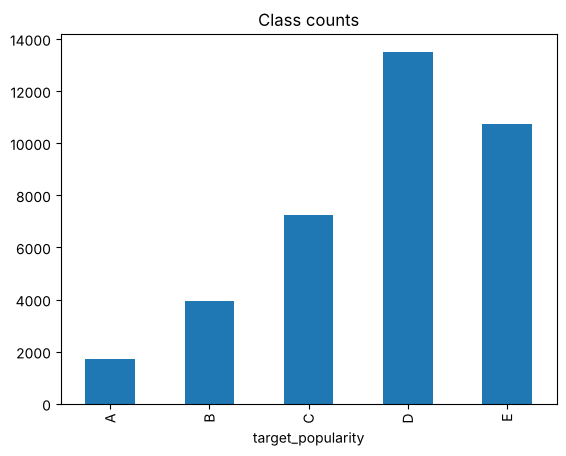

In [2]:
train['target_popularity'].value_counts().sort_index().plot.bar(title='Class counts');
print(train['target_popularity'].value_counts(normalize=True).sort_index().round(3))

### 2b. Missing values
Train has ~3–6% NA in 15 columns; test has none. Rows with NA have the same class mix as rows without, so missingness carries no signal. LightGBM handles NaN natively, so no imputation is needed.

In [3]:
na = train.isna().sum(); print(na[na>0]); print('test NA total:', test.isna().sum().sum())
print(pd.crosstab(train.isna().any(axis=1), train.target_popularity, normalize='index').round(3))

n_tokens_content              1055
n_unique_tokens               1115
num_hrefs                     1557
num_imgs                      1843
average_token_length          1079
num_keywords                   758
kw_max_avg                    1427
kw_avg_avg                    2269
self_reference_avg_sharess    1921
LDA_02                        1110
global_subjectivity           1126
global_sentiment_polarity     1106
avg_positive_polarity         1519
avg_negative_polarity         1454
title_subjectivity             727
dtype: int64
test NA total: 0
target_popularity      A      B     C      D      E
row_0                                              
False              0.047  0.107  0.19  0.363  0.292
True               0.045  0.105  0.20  0.365  0.285


### 2c. The classes are ordered
Feature averages move steadily from A to E: **A = most popular, E = least popular**.

In [4]:
cols = ['kw_avg_avg','self_reference_avg_sharess','num_hrefs','data_channel_is_world','data_channel_is_socmed','is_weekend']
train.groupby('target_popularity')[cols].mean().round(3)

,kw_avg_avg,self_reference_avg_sharess,num_hrefs,data_channel_is_world,data_channel_is_socmed,is_weekend
target_popularity,,,,,,
A,3954.476,12076.436,13.884,0.112,0.055,0.163
B,3522.870,9096.277,12.456,0.123,0.095,0.179
C,3261.929,7376.521,11.713,0.150,0.093,0.184
D,3045.064,5904.198,10.668,0.218,0.059,0.145
E,2857.947,4348.671,9.539,0.302,0.019,0.051


### 2d. Quirks
~1,000 articles have 0 words (scraping errors), `kw_min_min` is nearly categorical, and count features are heavily skewed. Skew doesn't affect tree models.

In [5]:
print('empty articles:', (train.n_tokens_content==0).sum())
print(train.kw_min_min.value_counts().head())

empty articles: 1078
kw_min_min
-1      21554
 4      11160
 217     4317
 0         75
 47         6
Name: count, dtype: int64


## Step 3 — Validation
Stratified 5-fold CV with **out-of-fold (OOF)** predictions: each training row is predicted by a model that never saw it. The OOF Macro F1 is our trusted score. The test set has only 2,500 rows, so the public leaderboard is noisy.

In [6]:
classes = list('ABCDE')
y = train['target_popularity'].map({c:i for i,c in enumerate(classes)}).values
macro = lambda yt, yp: f1_score(yt, yp, average='macro')

## Step 4 — Feature engineering
Collapse one-hot groups into single categories, plus a few ratios. **Effect on CV: roughly neutral** (0.3203 → 0.3205). A second batch of extra features *hurt* (0.3185), so it was dropped. Each idea was kept only if CV improved.

In [7]:
def add_features(d):
    d = d.copy()
    ch = ['lifestyle','entertainment','bus','socmed','tech','world']; chc = [f'data_channel_is_{c}' for c in ch]
    d['channel'] = np.where(d[chc].sum(axis=1)==0, 6, np.argmax(d[chc].values, axis=1))
    days = ['monday','tuesday','wednesday','thursday','friday','saturday','sunday']
    d['weekday'] = np.argmax(d[[f'weekday_is_{x}' for x in days]].values, axis=1)
    lda = [f'LDA_0{i}' for i in range(5)]
    d['lda_top'] = np.argmax(d[lda].values, axis=1); d['lda_max'] = d[lda].max(axis=1)
    d['empty_article'] = (d.n_tokens_content==0).astype(int)
    words = d.n_tokens_content.replace(0, np.nan)
    d['imgs_per_word'] = d.num_imgs / words; d['hrefs_per_word'] = d.num_hrefs / words
    d['self_href_ratio'] = d.num_self_hrefs / (d.num_hrefs + 1)
    d['kw_avg_spread'] = d.kw_max_avg - d.kw_min_avg; d['kw_avg_ratio'] = d.kw_avg_avg / (d.kw_max_avg + 1)
    d['selfref_spread'] = d.self_reference_max_shares - d.self_reference_min_shares
    d['sent_x_subj'] = d.global_sentiment_polarity * d.global_subjectivity
    return d

TR, TE = add_features(train), add_features(test)
features = [c for c in TE.columns if c != 'id']
X, Xt = TR[features], TE[features]
print(len(features), 'features')

71 features


## Step 5 — Hyperparameter tuning (Optuna)
25 trials searching LightGBM settings to maximise 3-fold CV Macro F1. It's slow (~30 min on 2 CPUs), so the best parameters are hard-coded below. Set `RUN_OPTUNA = True` to rerun the search.

In [8]:
RUN_OPTUNA = False
best = {'n_estimators': 600, 'num_leaves': 24, 'min_child_samples': 18, 'colsample_bytree': 0.512,
        'subsample': 0.725, 'reg_lambda': 0.192, 'reg_alpha': 0.0025}

if RUN_OPTUNA:
    import optuna
    sk3 = StratifiedKFold(3, shuffle=True, random_state=7)
    def objective(t):
        p = dict(n_estimators=t.suggest_int('n_estimators',200,900,step=100), learning_rate=0.03,
                 num_leaves=t.suggest_int('num_leaves',8,96,log=True), min_child_samples=t.suggest_int('min_child_samples',10,200,log=True),
                 colsample_bytree=t.suggest_float('colsample_bytree',0.2,0.9), subsample=t.suggest_float('subsample',0.5,1.0), subsample_freq=1,
                 reg_lambda=t.suggest_float('reg_lambda',1e-3,30,log=True), reg_alpha=t.suggest_float('reg_alpha',1e-3,10,log=True),
                 class_weight='balanced', verbose=-1, random_state=0)
        oof = np.zeros((len(X),5))
        for a,b in sk3.split(X,y): oof[b] = lgb.LGBMClassifier(**p).fit(X.iloc[a],y[a]).predict_proba(X.iloc[b])
        return macro(y, oof.argmax(1))
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=0))
    study.optimize(objective, n_trials=25); best = study.best_params
print(best)

{'n_estimators': 600, 'num_leaves': 24, 'min_child_samples': 18, 'colsample_bytree': 0.512, 'subsample': 0.725, 'reg_lambda': 0.192, 'reg_alpha': 0.0025}


## Step 6 — Train LightGBM: 5 seeds × 5 folds
`class_weight='balanced'` makes rare classes count more (the single biggest gain: ~0.27 → ~0.32). Averaging over seeds smooths out randomness. Each seed uses a different fold split.

In [9]:
params = dict(**best, learning_rate=0.03, subsample_freq=1, class_weight='balanced', verbose=-1)
SEEDS = [0, 1, 2, 3, 4]
oof = np.zeros((len(X),5)); tst = np.zeros((len(Xt),5))
for s in SEEDS:
    o = np.zeros((len(X),5))
    for a, b in StratifiedKFold(5, shuffle=True, random_state=100+s).split(X, y):
        m = lgb.LGBMClassifier(**params, random_state=s).fit(X.iloc[a], y[a])
        o[b] = m.predict_proba(X.iloc[b]); tst += m.predict_proba(Xt) / (5*len(SEEDS))
    oof += o / len(SEEDS)
    print(f'seed {s}: {macro(y, o.argmax(1)):.4f}')
print('seed-averaged OOF Macro F1:', round(macro(y, oof.argmax(1)), 4))

seed 0: 0.3177


seed 1: 0.3213


seed 2: 0.3226


seed 3: 0.3176


seed 4: 0.3203
seed-averaged OOF Macro F1: 0.3257


## Step 7 — Tune class weights for Macro F1
Multiply each class probability by a weight, then search for weights that maximise Macro F1. **Honest check:** tune on one half of the OOF rows, score on the other half (both directions).

In [10]:
def tune_weights(P, yt, rounds=3):
    w = np.ones(5)
    for _ in range(rounds):
        for k in range(5):
            best_s, best_v = macro(yt, (P*w).argmax(1)), w[k]
            for v in np.linspace(0.3, 4, 38):
                w2 = w.copy(); w2[k] = v; s = macro(yt, (P*w2).argmax(1))
                if s > best_s: best_s, best_v = s, v
            w[k] = best_v
    return w

idx = np.random.RandomState(0).permutation(len(y)); H = [idx[:len(y)//2], idx[len(y)//2:]]
honest = np.mean([macro(y[H[1-i]], (oof[H[1-i]]*tune_weights(oof[H[i]], y[H[i]])).argmax(1)) for i in (0,1)])
print('argmax OOF:', round(macro(y, oof.argmax(1)),4), '| honest tuned:', round(honest,4))
w = tune_weights(oof, y)
print('final weights:', dict(zip(classes, w.round(2))))

argmax OOF: 0.3257 | honest tuned: 0.3289


final weights: {'A': np.float64(0.8), 'B': np.float64(1.0), 'C': np.float64(1.0), 'D': np.float64(1.1), 'E': np.float64(0.9)}


## Step 8 — Error analysis

     A     B     C     D     E
A  333   440   315   391   236
B  370   969  1008  1036   562
C  412  1259  2042  2408  1109
D  598  1506  2288  5706  3409
E  401   761   724  3113  5748
A    0.174
B    0.218
C    0.300
D    0.436
E    0.527
dtype: float64


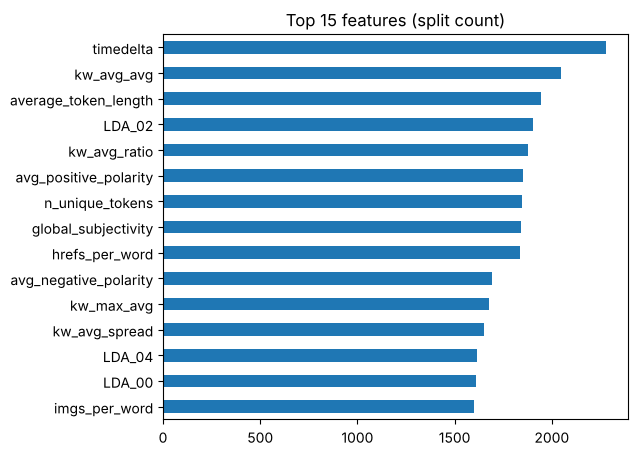

In [11]:
pred = (oof*w).argmax(1)
print(pd.DataFrame(confusion_matrix(y, pred), index=classes, columns=classes))
print(pd.Series(f1_score(y, pred, average=None), index=classes).round(3))
imp = pd.Series(lgb.LGBMClassifier(**params, random_state=0).fit(X, y).feature_importances_, index=features)
imp.sort_values().tail(15).plot.barh(title='Top 15 features (split count)', figsize=(6,5));

## Experiments that did NOT help (kept out of the final model)
| Experiment | CV Macro F1 |
|---|---|
| Tuned LightGBM alone (final) | **0.3266** argmax / **0.3305** honest-tuned |
| + CatBoost + XGBoost averaged | 0.3219 / 0.3257 |
| LightGBM 0.6 + XGBoost 0.4 | 0.3241 / 0.3293 |
| Stacking (logistic regression on all models + ordinal regressor) | 0.3093 / 0.3284 |
| Extra feature batch 2 | 0.3185 (vs 0.3205) |

CatBoost (0.318) and XGBoost (0.320) were individually weaker than tuned LightGBM, so blending them in pulled the score down.

## Step 9 — Submission

In [12]:
test_pred = (tst * w).argmax(1)
submission = pd.DataFrame({'id': test['id'], 'target_popularity': [classes[i] for i in test_pred]})
assert len(submission)==len(test) and submission.id.is_unique and submission.target_popularity.isin(classes).all()
submission.to_csv('submission.csv', index=False)
print(submission.target_popularity.value_counts(normalize=True).sort_index().round(3))
submission.head()

target_popularity
A    0.085
B    0.177
C    0.191
D    0.310
E    0.238
Name: proportion, dtype: float64


,id,target_popularity
0,9516,D
1,35906,B
2,20105,D
3,35214,E
4,3184,A
